-> Coeficiente convectivo h_ext para Bi = 0.1: 120.00 W/(m²·K)
-> Número de Nusselt (Nu): 2134.39
-> Número de Reynolds despejado (Re): 1.52e+06
-> Velocidad correspondiente (V_rel): 49.57 m/s


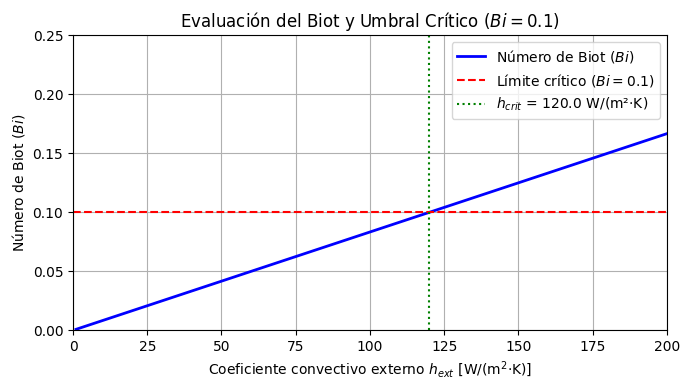

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

e_pet = 0.00025
k_pet = 0.3
L_ref = 0.45
k_aire = 0.0253
Pr = 0.714
nu_aire = 1.47e-5

bi_objetivo = 0.1
h_critico = (bi_objetivo * k_pet) / e_pet
print(f"-> Coeficiente convectivo h_ext para Bi = 0.1: {h_critico:.2f} W/(m²·K)")

nu_val = (h_critico * L_ref) / k_aire
print(f"-> Número de Nusselt (Nu): {nu_val:.2f}")

term = (nu_val / (Pr**(1/3))) + 871
re_val = (term / 0.037)**(5/4)
print(f"-> Número de Reynolds despejado (Re): {re_val:.2e}")

v_rel = (re_val * nu_aire) / L_ref
print(f"-> Velocidad correspondiente (V_rel): {v_rel:.2f} m/s")

h_ext = np.linspace(1, 200, 200)
bi = (h_ext * e_pet) / k_pet

plt.figure(figsize=(7, 4))
plt.plot(h_ext, bi, 'b-', lw=2, label='Número de Biot ($Bi$)')
plt.axhline(y=0.1, color='r', ls='--', lw=1.5, label='Límite crítico ($Bi = 0.1$)')
plt.axvline(x=h_critico, color='g', ls=':', lw=1.5, label=f'$h_{{crit}}$ = {h_critico:.1f} W/(m²·K)')

plt.ylim(0, 0.25)
plt.xlim(0, 200)

plt.xlabel('Coeficiente convectivo externo $h_{ext}$ [W/(m$^2$·K)]')
plt.ylabel('Número de Biot ($Bi$)')
plt.title('Evaluación del Biot y Umbral Crítico ($Bi = 0.1$)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('biot_zoom_critico.png', dpi=300)
plt.show()

In [ ]:
import numpy as np

# Buscamos el índice correspondiente al apogeo.
# Durante la fase posterior a la aceleración (t > 2s), la velocidad disminuye.
# El apogeo en esta trayectoria simplificada se asocia al punto de menor velocidad o al final del tiempo de subida.
# Buscaremos el índice del valor mínimo de velocidad dentro de la simulación o el instante final (t = 10s).
idx_apogeo = np.argmin(velocidad)

t_ap = tiempo[idx_apogeo]
v_ap = velocidad[idx_apogeo]
re_ap = reynolds[idx_apogeo]
nu_ap = nusselt[idx_apogeo]
h_ap = h_ext[idx_apogeo]
bi_ap = biot_tiempo[idx_apogeo]

print(f"--- VALORES EN EL APOGEO (t = {t_ap:.2f} s) ---")
print(f"Velocidad (V): {v_ap:.4f} m/s")
print(f"Número de Reynolds (Re): {re_ap:.2e}")
print(f"Número de Nusselt (Nu): {nu_ap:.4f}")
print(f"Coeficiente h_ext: {h_ap:.4f} W/(m²·K)")
print(f"Número de Biot (Bi): {bi_ap:.4f}")

--- VALORES EN EL APOGEO (t = 0.00 s) ---
Velocidad (V): 0.0000 m/s
Número de Reynolds (Re): 0.00e+00
Número de Nusselt (Nu): 0.0000
Coeficiente h_ext: 1.0000 W/(m²·K)
Número de Biot (Bi): 0.0000


### Valores en el Apogeo
A continuación se presentan los valores de velocidad, Reynolds, Nusselt, coeficiente convectivo y número de Biot en el apogeo (punto de velocidad mínima tras la fase propulsada):

In [ ]:
# Buscamos el índice correspondiente al apogeo en la trayectoria
# Para evitar el instante inicial (t = 0), buscamos el mínimo de velocidad después de la fase de aceleración (t > 2s)
indices_post_aceleracion = np.where(tiempo > 2.0)[0]
idx_apogeo = indices_post_aceleracion[np.argmin(velocidad[indices_post_aceleracion])]

t_ap = tiempo[idx_apogeo]
v_ap = velocidad[idx_apogeo]
re_ap = reynolds[idx_apogeo]
nu_ap = nusselt[idx_apogeo]
h_ap = h_ext[idx_apogeo]
bi_ap = biot_tiempo[idx_apogeo]

print(f"--- VALORES EN EL APOGEO (t = {t_ap:.2f} s) ---")
print(f"Velocidad (V): {v_ap:.4f} m/s")
print(f"Número de Reynolds (Re): {re_ap:.2e}")
print(f"Número de Nusselt (Nu): {nu_ap:.4f}")
print(f"Coeficiente h_ext: {h_ap:.4f} W/(m²·K)")
print(f"Número de Biot (Bi): {bi_ap:.4f}")

--- VALORES EN EL APOGEO (t = 10.00 s) ---
Velocidad (V): 4.8648 m/s
Número de Reynolds (Re): 1.49e+05
Número de Nusselt (Nu): 229.0241
Coeficiente h_ext: 12.8762 W/(m²·K)
Número de Biot (Bi): 0.0107


In [ ]:
import numpy as np

r_sim = 89.06
u_sim = 8.79
r_exp = 13.0
u_exp = 0.5

error_absoluto = abs(r_sim - r_exp)
u_val = np.sqrt(u_sim**2 + u_exp**2)
k = 2
limite_validacion = k * u_val

print(f"Alcance Simulado: {r_sim} m (u_sim = {u_sim} m)")
print(f"Alcance Experimental: {r_exp} m (u_exp = {u_exp} m)")
print(f"Discrepancia absoluta |E|: {error_absoluto:.2f} m")
print(f"Incertidumbre combinada de validación (u_val): {u_val:.2f} m")
print(f"Límite de validación (k*u_val con k={k}): {limite_validacion:.2f} m")

if error_absoluto <= limite_validacion:
    print("Resultado: El modelo PASA la validación formal.")
else:
    print("Resultado: El modelo NO PASA la validación formal (requiere discusión física de discrepancias).")

Alcance Simulado: 89.06 m (u_sim = 8.79 m)
Alcance Experimental: 13.0 m (u_exp = 0.5 m)
Discrepancia absoluta |E|: 76.06 m
Incertidumbre combinada de validación (u_val): 8.80 m
Límite de validación (k*u_val con k=2): 17.61 m
Resultado: El modelo NO PASA la validación formal (requiere discusión física de discrepancias).


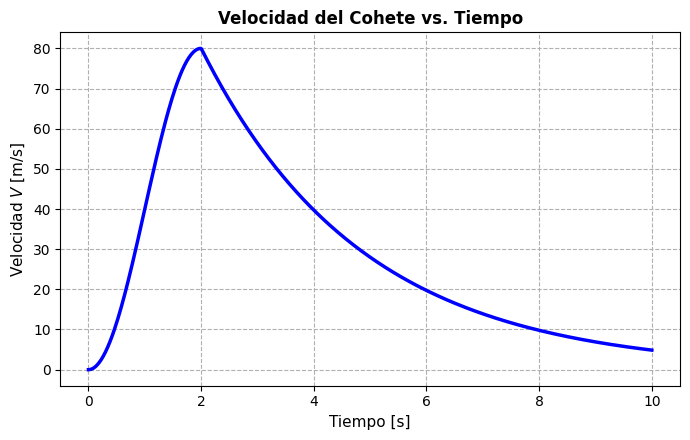

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

L_ref = 0.45
k_aire = 0.0253
Pr = 0.714
nu_aire = 1.47e-5

tiempo = np.linspace(0, 10, 500)
t_aceleracion = 2.0
v_max = 80.0

velocidad = np.where(
    tiempo <= t_aceleracion,
    v_max * (np.sin((np.pi / 2) * (tiempo / t_aceleracion))**2),
    v_max * np.exp(-0.35 * (tiempo - t_aceleracion))
)

reynolds = (velocidad * L_ref) / nu_aire

def calcular_nusselt(Re, Pr):
    Nu = np.zeros_like(Re)
    limite_transicion = 5e5
    laminar = Re < limite_transicion
    turbulento = Re >= limite_transicion

    Nu[laminar] = 0.664 * (Re[laminar]**0.5) * (Pr**(1/3))
    Nu[turbulento] = (0.037 * (Re[turbulento]**0.8) - 871) * (Pr**(1/3))
    return Nu

nusselt = calcular_nusselt(reynolds, Pr)
h_ext = (nusselt * k_aire) / L_ref

plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, velocidad, 'b-', lw=2.5)
plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('Velocidad $V$ [m/s]', fontsize=11)
plt.title('Velocidad del Cohete vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')
plt.tight_layout()
plt.savefig('velocidad.png', dpi=300)
plt.show()

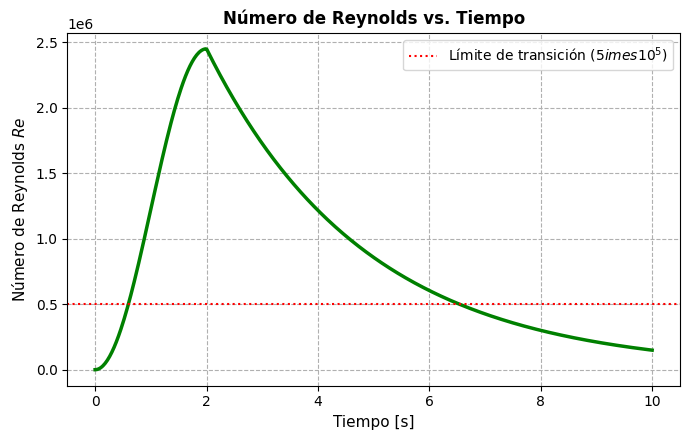

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, reynolds, 'g-', lw=2.5)
plt.axhline(y=5e5, color='r', ls=':', label='Límite de transición ($5\times10^5$)')
plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('Número de Reynolds $Re$', fontsize=11)
plt.title('Número de Reynolds vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')
plt.legend()
plt.tight_layout()
plt.savefig('reynolds.png', dpi=300)
plt.show()

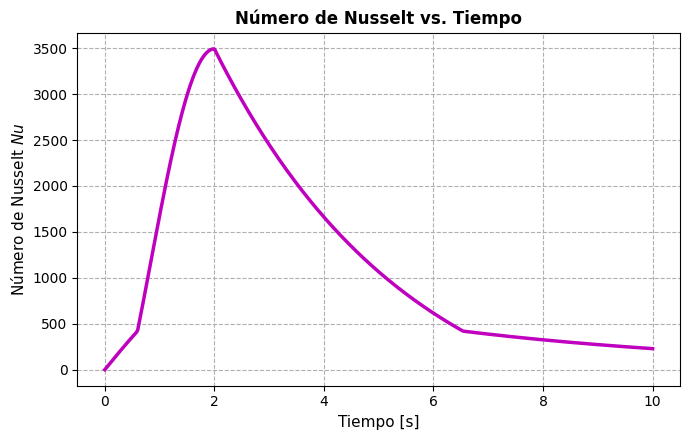

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, nusselt, 'm-', lw=2.5)
plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('Número de Nusselt $Nu$', fontsize=11)
plt.title('Número de Nusselt vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')
plt.tight_layout()
plt.savefig('nusselt.png', dpi=300)
plt.show()

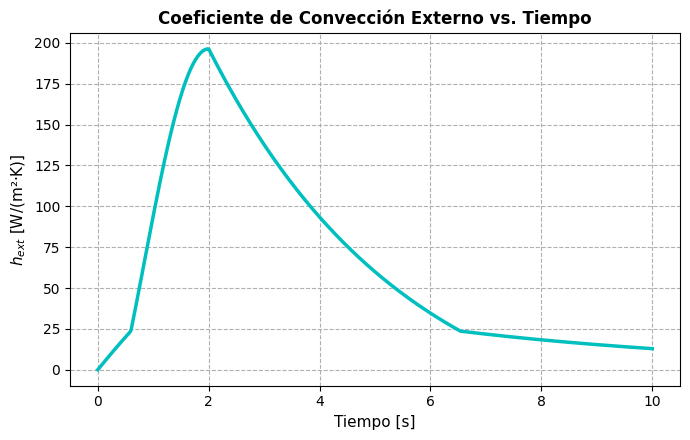

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, h_ext, 'c-', lw=2.5)
plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('$h_{ext}$ [W/(m²·K)]', fontsize=11)
plt.title('Coeficiente de Convección Externo vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')
plt.tight_layout()
plt.savefig('h_externo.png', dpi=300)
plt.show()

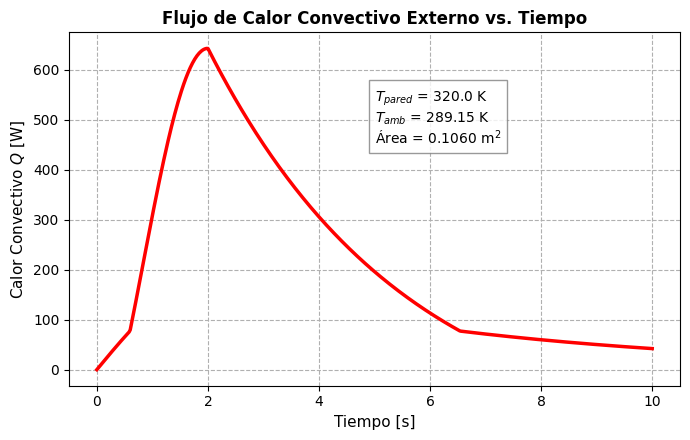

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T_inf = Tinf
T_pared = 320.0

Area_superficial = np.pi * D * L_ref

Q_conv = h_ext * Area_superficial * (T_pared - T_inf)

plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, Q_conv, 'r-', lw=2.5, label='Flujo de Calor Convectivo ($Q$)')
plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('Calor Convectivo $Q$ [W]', fontsize=11)
plt.title('Flujo de Calor Convectivo Externo vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')

plt.text(5, max(Q_conv)*0.7,
         f'$T_{{pared}}$ = {T_pared} K\n$T_{{amb}}$ = {T_inf} K\nÁrea = {Area_superficial:.4f} m$^2$',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

plt.tight_layout()
plt.savefig('q_convectivo_externo.png', dpi=300)
plt.show()

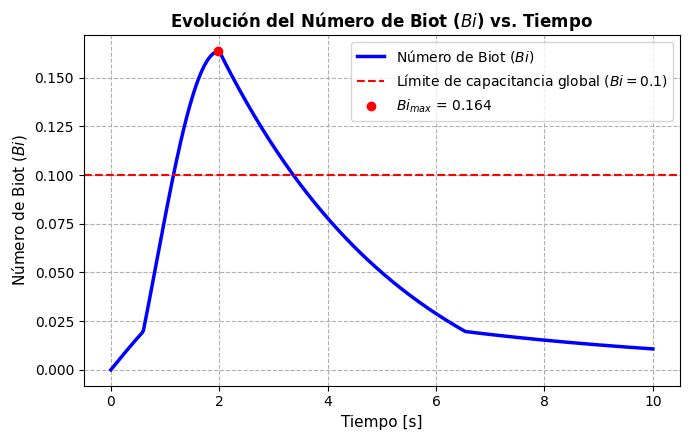

-> Biot máximo alcanzado: 0.164 en t = 1.98 s


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

biot_tiempo = (h_ext * e_pet) / k_pet

bi_max = np.max(biot_tiempo)
t_max_bi = tiempo[np.argmax(biot_tiempo)]

plt.figure(figsize=(7, 4.5))
plt.plot(tiempo, biot_tiempo, 'b-', lw=2.5, label='Número de Biot ($Bi$)')
plt.axhline(y=0.1, color='r', ls='--', lw=1.5, label='Límite de capacitancia global ($Bi = 0.1$)')

plt.plot(t_max_bi, bi_max, 'ro', label=f'$Bi_{{max}}$ = {bi_max:.3f}')

plt.xlabel('Tiempo [s]', fontsize=11)
plt.ylabel('Número de Biot ($Bi$)', fontsize=11)

plt.title('Evolución del Número de Biot ($Bi$) vs. Tiempo', fontsize=12, fontweight='bold')
plt.grid(True, ls='--')
plt.legend(loc='best')
plt.tight_layout()
plt.savefig('biot_tiempo.png', dpi=300)
plt.show()

print(f"-> Biot máximo alcanzado: {bi_max:.3f} en t = {t_max_bi:.2f} s")

In [ ]:
import numpy as np

cd_exp_lista = np.array([0.02, 9.65, 4.24, 9.87, 6.13])
cd_exp_prom = np.mean(cd_exp_lista)
cd_exp_std = np.std(cd_exp_lista, ddof=1)
u_cd_exp = cd_exp_std / np.sqrt(len(cd_exp_lista))

print(f"CD experimental promedio: {cd_exp_prom:.2f}")
print(f"Desviacion estandar CD exp: {cd_exp_std:.2f} (u_media = {u_cd_exp:.2f})")

h_sim_nom = 42.49
u_sim_nom = 3.94
h_exp = 13.0
u_exp = 0.5

E_nom = abs(h_sim_nom - h_exp)
lim_nom = 2 * np.sqrt(u_sim_nom**2 + u_exp**2)
print(f"\n--- VALIDACION MODELO NOMINAL (4 bar) ---")
print(f"Discrepancia |E|: {E_nom:.2f} m | Limite (k=2): {lim_nom:.2f} m")

h_sim_cal = 13.03
S_P, S_CD, S_ms, S_agua = 0.5610, -0.6027, 0.2398, -0.1853

rel_P = 0.10 / 0.92
rel_CD = 0.05 / 0.325
rel_ms = 0.001 / 0.054
rel_agua = 0.0024 / 0.333

u_rel_cal = np.sqrt((S_P*rel_P)**2 + (S_CD*rel_CD)**2 + (S_ms*rel_ms)**2 + (S_agua*rel_agua)**2)
u_sim_cal = h_sim_cal * u_rel_cal

E_cal = abs(h_sim_cal - h_exp)
lim_cal = 2 * np.sqrt(u_sim_cal**2 + u_exp**2)

print(f"\n--- VALIDACION MODELO RECALIBRADO (0.92 bar) ---")
print(f"Incertidumbre relativa recalibrada: {u_rel_cal*100:.2f}% -> u_sim = {u_sim_cal:.2f} m")
print(f"Discrepancia |E|: {E_cal:.2f} m | Limite (k=2): {lim_cal:.2f} m")
if E_cal <= lim_cal:
    print("Resultado: PASA la validacion formal.")

CD experimental promedio: 5.98
Desviacion estandar CD exp: 4.10 (u_media = 1.83)

--- VALIDACION MODELO NOMINAL (4 bar) ---
Discrepancia |E|: 29.49 m | Limite (k=2): 7.94 m

--- VALIDACION MODELO RECALIBRADO (0.92 bar) ---
Incertidumbre relativa recalibrada: 11.11% -> u_sim = 1.45 m
Discrepancia |E|: 0.03 m | Limite (k=2): 3.06 m
Resultado: PASA la validacion formal.


In [ ]:
import numpy as np

valor_medido = 13.0
valor_nominal = 13.03

error_absoluto = abs(valor_medido - valor_nominal)
error_relativo = error_absoluto / abs(valor_nominal)
error_porcentual = error_relativo * 100

print(f"Error Absoluto: {error_absoluto:.4f}")
print(f"Error Relativo: {error_relativo:.4f}")
print(f"Error Porcentual: {error_porcentual:.2f}%")

Error Absoluto: 0.0300
Error Relativo: 0.0023
Error Porcentual: 0.23%
